# Parte 3: Visualizações do mapa
**Responsável:** Erica · Projeto final de Aprendizado Não Supervisionado (SOM)

**Objetivo desta etapa:** ler o mapa treinado na Parte 2 com quatro visualizações (U-Matrix, component planes, hit map e
`Channel` sobreposto) e testar a hipótese da EDA: o mapa deve separar um lado "mercearia/limpeza" (Varejo) de um lado
"frescos/congelados" (Horeca).

**Convenção dos gráficos:** o eixo x é o 1º índice do neurônio e o eixo y é o 2º índice, a mesma ordem de `som.winner(x)`
e das colunas `bmu_x`/`bmu_y` que a Parte 4 salva. Todos os mapas deste notebook e dos próximos usam essa orientação.

## 1. Bibliotecas, dados e mapa

In [1]:
import os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from minisom import MiniSom

SEED = 42
np.random.seed(SEED)

# Paleta do projeto (a mesma da Parte 1)
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
COR_CANAL = {"Horeca": AZUL, "Varejo": LARANJA}
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#d95926", "#f0efec", "#2a78d6"])
# Clusters: cores diferentes das do canal, para não confundir "cluster" com "Horeca/Varejo"
COR_CLUSTER = ["#1baf7a", "#6250d6", "#eda100"]          # aqua, violeta, amarelo
MARCA_CLUSTER = ["o", "s", "^"]
CINZAS = LinearSegmentedColormap.from_list("cinzas", ["#f4f4f2", "#52514e"])   # U-Matrix: escuro = distância maior

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.edgecolor": "#888", "axes.labelcolor": "#222", "xtick.color": "#444", "ytick.color": "#444",
})
os.makedirs("figuras", exist_ok=True)

GASTOS = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
X_scaled = pd.read_csv("dados/X_scaled.csv").values
df = pd.read_csv("dados/dados_preprocessados.csv")
print("X_scaled:", X_scaled.shape, "| df:", df.shape)

X_scaled: (440, 6) | df: (440, 16)


In [2]:
# Mapa treinado na Parte 2 (Roger)
try:
    with open("dados/som.pkl", "rb") as f:
        som = pickle.load(f)
except Exception as erro_pickle:
    # Plano B: se o pickle não abrir (versão diferente de numpy/minisom), recria o mapa a partir dos pesos salvos
    print("som.pkl não abriu, recriando a partir de dados/som_pesos.npy:", erro_pickle)
    som = MiniSom(10, 10, X_scaled.shape[1], sigma=2.0, learning_rate=0.3, random_seed=SEED)
    som._weights = np.load("dados/som_pesos.npy")

LADO = som.get_weights().shape[0]
bmu = np.array([som.winner(x) for x in X_scaled])          # neurônio vencedor (BMU) de cada cliente
print("Mapa:", som.get_weights().shape, "| QE:", round(som.quantization_error(X_scaled), 4),
      "| TE:", round(som.topographic_error(X_scaled), 4))

def eixo_mapa(ax, titulo=""):
    """Padroniza um eixo de mapa: x = 1º índice do neurônio, y = 2º índice (mesma convenção de som.winner)."""
    ax.set_xlim(0, LADO); ax.set_ylim(0, LADO); ax.set_aspect("equal")
    ax.set_xticks(np.arange(LADO) + 0.5); ax.set_xticklabels(range(LADO))
    ax.set_yticks(np.arange(LADO) + 0.5); ax.set_yticklabels(range(LADO))
    ax.grid(False); ax.tick_params(length=0, labelsize=8)
    ax.set_xlabel("x (bmu_x)"); ax.set_ylabel("y (bmu_y)")
    if titulo: ax.set_title(titulo)

Mapa: (10, 10, 6) | QE: 0.8977 | TE: 0.05


## 2. U-Matrix
Para cada neurônio, a U-Matrix mostra a distância média entre os seus pesos e os pesos dos vizinhos (`som.distance_map()`,
normalizada de 0 a 1).
- **Escuro = distância grande = fronteira** entre grupos (os vizinhos são muito diferentes).
- **Claro = distância pequena = interior de um grupo** (os vizinhos são parecidos).

(Atenção: o PROJETO.md dizia o contrário, "claro = fronteira". Isso depende do mapa de cores. Aqui usamos uma escala de cinza do claro ao escuro,
como nos exemplos do `minisom` com `bone_r`.)

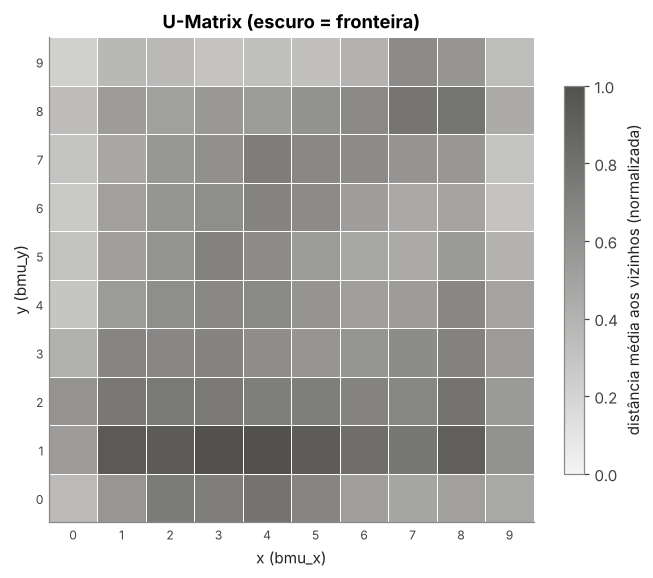

Distância média por coluna y (de baixo para cima): [0.58 0.84 0.7  0.61 0.56 0.52 0.51 0.54 0.58 0.39]
Distância média por linha x (da esquerda para a direita): [0.36 0.59 0.64 0.66 0.67 0.63 0.58 0.6  0.66 0.44]


In [3]:
U = som.distance_map()
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.pcolormesh(U.T, cmap=CINZAS, vmin=0, vmax=1, edgecolors="white", linewidth=0.6)
eixo_mapa(ax, "U-Matrix (escuro = fronteira)")
fig.colorbar(im, ax=ax, shrink=0.8, label="distância média aos vizinhos (normalizada)")
plt.tight_layout(); plt.savefig("figuras/03_umatrix.png", bbox_inches="tight"); plt.show()

print("Distância média por coluna y (de baixo para cima):", U.mean(axis=0).round(2))
print("Distância média por linha x (da esquerda para a direita):", U.mean(axis=1).round(2))

**Leitura:**
- A fronteira mais forte é uma **faixa escura horizontal em y = 1**, de x = 1 a x = 8 (valores de 0,8 a 1,0). Ela isola a
  **linha de baixo (y = 0)** do resto do mapa. Como os component planes vão mostrar, ali caem clientes com gasto quase nulo
  em alguma categoria (Fresh ou Delicassen), os candidatos a outlier da EDA.
- As **bordas esquerda (x = 0), direita (x = 9) e de cima (y = 9)** são claras: regiões homogêneas, ou seja, grupos compactos.
- Há uma segunda fronteira, mais fraca, perto do canto superior direito (x 7-8, y 8).
- O **centro** tem tons médios (0,5 a 0,7), sem paredes nítidas. Os grupos do meio do mapa **se misturam aos poucos**, e não
  há uma separação limpa em "ilhas". Isso já antecipa que o silhouette dos clusters (Parte 4) vai ser modesto.

## 3. Component planes
Um mapa por variável: a cor de cada neurônio é o peso daquela variável (em z-score, porque o SOM foi treinado em `X_scaled`).
Azul = gasto acima da média, laranja = abaixo, cinza claro = perto da média.

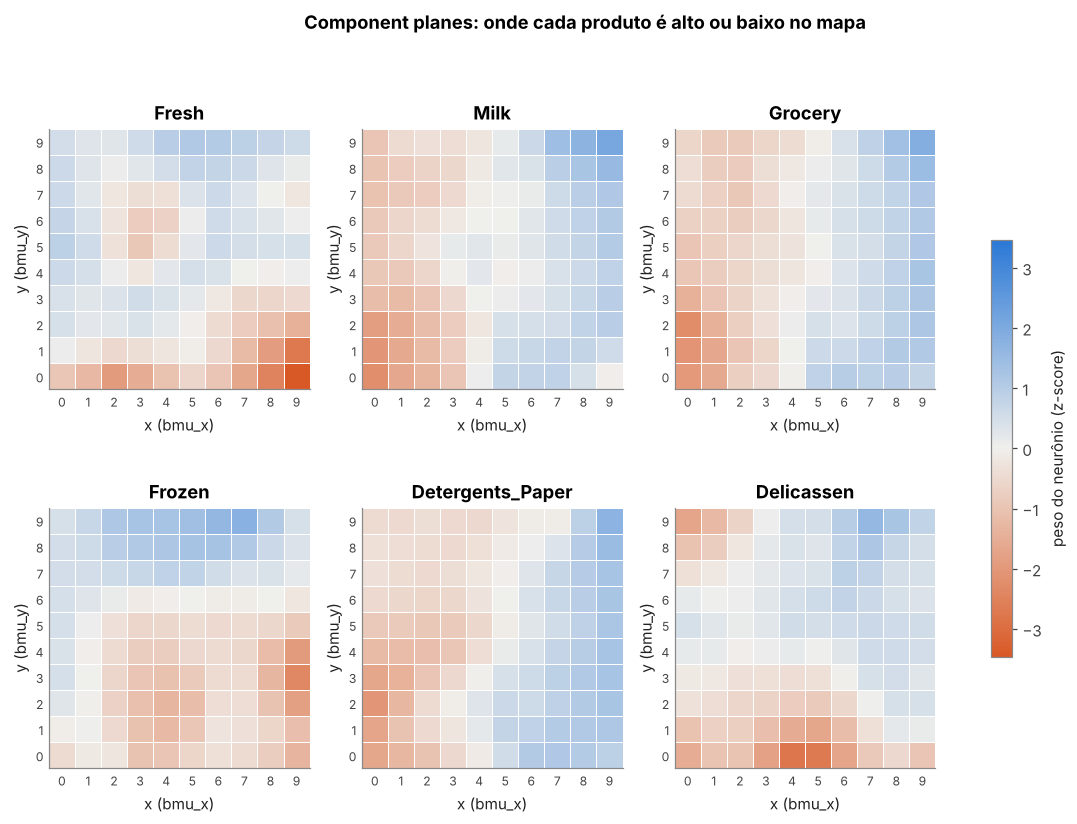

,metade esquerda (x 0-4),metade direita (x 5-9)
Fresh,0.01,-0.17
Milk,-0.71,0.65
Grocery,-0.71,0.71
Frozen,0.00,-0.23
Detergents_Paper,-0.68,0.73
Delicassen,-0.38,0.20


In [4]:
W = som.get_weights()
lim = np.abs(W).max()
fig, axes = plt.subplots(2, 3, figsize=(13, 8.2))
for i, (ax, col) in enumerate(zip(axes.flat, GASTOS)):
    im = ax.pcolormesh(W[:, :, i].T, cmap=DIVERGENTE, vmin=-lim, vmax=lim, edgecolors="white", linewidth=0.4)
    eixo_mapa(ax, col)
fig.colorbar(im, ax=axes, shrink=0.6, label="peso do neurônio (z-score)")
fig.suptitle("Component planes: onde cada produto é alto ou baixo no mapa", fontweight="bold")
plt.savefig("figuras/03_component_planes.png", bbox_inches="tight"); plt.show()

# resumo numérico: média dos pesos por metade do mapa
esq, dir_ = W[:5, :, :].reshape(-1, 6).mean(0), W[5:, :, :].reshape(-1, 6).mean(0)
display(pd.DataFrame({"metade esquerda (x 0-4)": esq, "metade direita (x 5-9)": dir_}, index=GASTOS).round(2))

**Leitura:**
- **`Milk`, `Grocery` e `Detergents_Paper` têm o mesmo desenho:** baixos à esquerda e altos à direita. É o bloco
  "mercearia/limpeza" da EDA (correlação de 0,80 entre Grocery e Detergents_Paper após o log), que aparece aqui como um **gradiente da esquerda para a direita**.
- **`Frozen` segue outro eixo:** é alto em **toda a parte de cima** do mapa (y ≥ 7) e baixo embaixo, no meio (x 3-5, y 1-3),
  e na borda direita (x = 9, y 3-5).
- **`Fresh`** é alto na parte de cima e na borda esquerda e **muito baixo no canto inferior direito** (z ≈ −3,5 em x = 9, y = 0):
  ali estão clientes que compram mercearia, mas quase nada de frescos.
- **`Delicassen`** é alto no canto superior direito e muito baixo embaixo, no meio (x 3-6, y 0-1).
- **Hipótese da EDA confirmada, com um detalhe:** o mapa separa os dois blocos em **eixos diferentes**. O eixo horizontal é
  "mercearia/limpeza" e o vertical é "congelados/frescos". O canto superior direito junta os dois: clientes que compram
  **acima da média em quase tudo**.

## 4. Hit map
Quantos clientes têm cada neurônio como vencedor (`som.activation_response`).

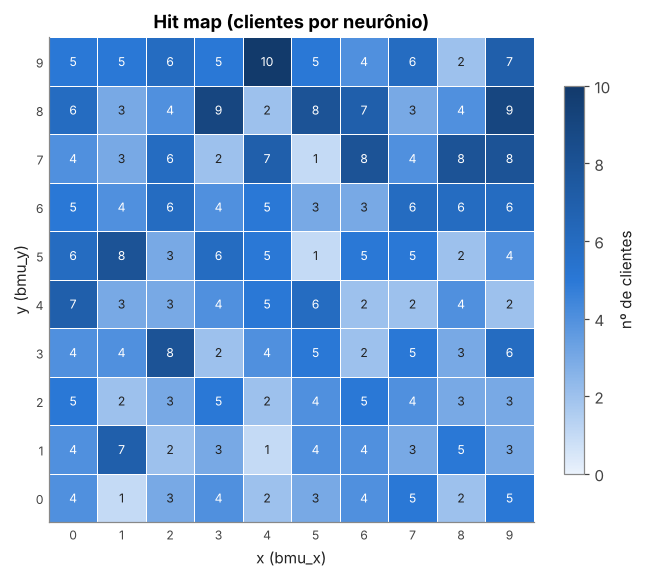

Neurônios vazios: 0 | mínimo: 1 | máximo: 10 | média: 4.4
Neurônios com 1 cliente (x, y): [(1, 0), (4, 1), (5, 5), (5, 7)]


In [5]:
hits = som.activation_response(X_scaled)
AZUIS = LinearSegmentedColormap.from_list("azuis", ["#eaf2fc", "#2a78d6", "#123a6b"])
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.pcolormesh(hits.T, cmap=AZUIS, vmin=0, edgecolors="white", linewidth=0.6)
for x in range(LADO):
    for y in range(LADO):
        v = int(hits[x, y])
        ax.text(x + 0.5, y + 0.5, v, ha="center", va="center", fontsize=8,
                color="white" if v >= 4 else "#222")
eixo_mapa(ax, "Hit map (clientes por neurônio)")
fig.colorbar(im, ax=ax, shrink=0.8, label="nº de clientes")
plt.tight_layout(); plt.savefig("figuras/03_hitmap.png", bbox_inches="tight"); plt.show()

print("Neurônios vazios:", int((hits == 0).sum()), "| mínimo:", int(hits.min()), "| máximo:", int(hits.max()),
      "| média:", hits.mean().round(1))
print("Neurônios com 1 cliente (x, y):", [tuple(int(v) for v in p) for p in np.argwhere(hits == 1)])

**Leitura:**
- **Nenhum neurônio ficou vazio** e a ocupação vai de 1 a 10 clientes (média de 4,4). O mapa 10×10 está bem dimensionado
  para 440 clientes: não sobra neurônio "morto" e nenhum concentra uma fatia grande da base.
- Só 4 neurônios têm 1 cliente: (1, 0), (4, 1), (5, 5) e (5, 7). Os dois primeiros ficam na faixa de baixo, colados à
  fronteira mais escura da U-Matrix: são candidatos a **neurônios isolados**, outro sinal de outlier que a Parte 4 vai conferir.

## 5. `Channel` sobreposto ao mapa (validação externa)
O SOM **não viu** o canal no treino. Se Horeca e Varejo caírem em regiões diferentes, é sinal de que o mapa capturou uma
estrutura real de negócio. À esquerda, cada cliente é um ponto no seu BMU (com um pequeno deslocamento aleatório para não
sobrepor). À direita, a proporção de Varejo em cada neurônio.

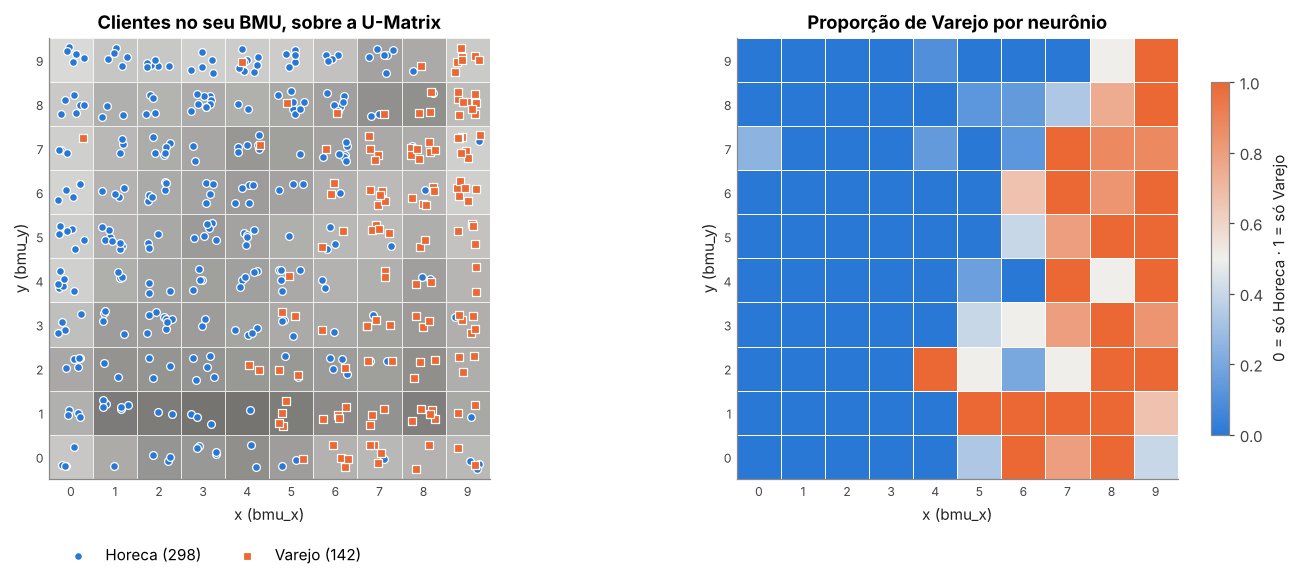

Pureza do canal por neurônio: 92.3%
Neurônios só Horeca: 53 | só Varejo: 19 | mistos: 28
  x 0-3: 178 clientes, 1% Varejo
  x 4-6: 127 clientes, 24% Varejo
  x 7-9: 135 clientes, 81% Varejo


In [6]:
rng = np.random.default_rng(SEED)
desloc = rng.uniform(-0.3, 0.3, size=bmu.shape)
pos = bmu + 0.5 + desloc
eh_varejo = (df["Canal"] == "Varejo").values

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
ax = axes[0]
ax.pcolormesh(U.T, cmap=CINZAS, vmin=0, vmax=1, edgecolors="white", linewidth=0.6, alpha=0.8)
for canal, marca in [("Horeca", "o"), ("Varejo", "s")]:
    m = (df["Canal"] == canal).values
    ax.scatter(pos[m, 0], pos[m, 1], s=26, marker=marca, color=COR_CANAL[canal], edgecolor="white",
               linewidth=0.8, label=f"{canal} ({m.sum()})", zorder=3)
eixo_mapa(ax, "Clientes no seu BMU, sobre a U-Matrix")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2, frameon=False)

ax = axes[1]
prop = np.full((LADO, LADO), np.nan)
for x in range(LADO):
    for y in range(LADO):
        m = (bmu[:, 0] == x) & (bmu[:, 1] == y)
        if m.any():
            prop[x, y] = eh_varejo[m].mean()
CANAL_DIV = LinearSegmentedColormap.from_list("canal", [AZUL, "#f0efec", LARANJA])
im = ax.pcolormesh(prop.T, cmap=CANAL_DIV, vmin=0, vmax=1, edgecolors="white", linewidth=0.6)
eixo_mapa(ax, "Proporção de Varejo por neurônio")
fig.colorbar(im, ax=ax, shrink=0.8, label="0 = só Horeca · 1 = só Varejo")
plt.tight_layout(); plt.savefig("figuras/03_canal_sobre_umatrix.png", bbox_inches="tight"); plt.show()

# Pureza: % de clientes que estão num neurônio cuja maioria é do seu próprio canal
maioria_varejo = prop[bmu[:, 0], bmu[:, 1]] >= 0.5
pureza = (maioria_varejo == eh_varejo).mean()
print(f"Pureza do canal por neurônio: {pureza:.1%}")
print("Neurônios só Horeca:", int((prop == 0).sum()), "| só Varejo:", int((prop == 1).sum()),
      "| mistos:", int(((prop > 0) & (prop < 1)).sum()))
for lado, m in [("x 0-3", bmu[:, 0] <= 3), ("x 4-6", (bmu[:, 0] >= 4) & (bmu[:, 0] <= 6)), ("x 7-9", bmu[:, 0] >= 7)]:
    print(f"  {lado}: {m.sum():3d} clientes, {eh_varejo[m].mean():.0%} Varejo")

**Leitura:**
- **A separação por canal é forte:** o Horeca (azul) ocupa a metade esquerda do mapa e o Varejo (laranja) se concentra à direita
  (nas colunas x 0-3 só 1% é Varejo; nas colunas x 7-9, 81%),
  exatamente onde `Milk`, `Grocery` e `Detergents_Paper` são altos. **92% dos clientes** estão num neurônio cuja maioria é do seu próprio canal,
  sem o SOM ter visto o canal.
- **A transição não é limpa:** na faixa do meio (x 4-6, com 24% de Varejo) há vários neurônios mistos (28 dos 100 neurônios têm os dois canais). São clientes Horeca que compram bastante
  mercearia, ou Varejo que compra pouco. Isso combina com a U-Matrix sem paredes fortes no centro.
- **Conclusão para o grupo:** o mapa confirma a hipótese da EDA (eixo mercearia/limpeza = Varejo; frescos/congelados = Horeca)
  e mostra algo que a EDA não mostrava. O canto superior direito (x 7-8, y 8-9) é misto e reúne clientes grandes que compram
  de tudo, dos dois canais. Isso é material para a Parte 6 nomear os perfis.

## 6. Figura-resumo para a apresentação
As quatro leituras num só gráfico, para o slide: a U-Matrix, o eixo mercearia (`Grocery`), o eixo congelados (`Frozen`) e a proporção de Varejo.

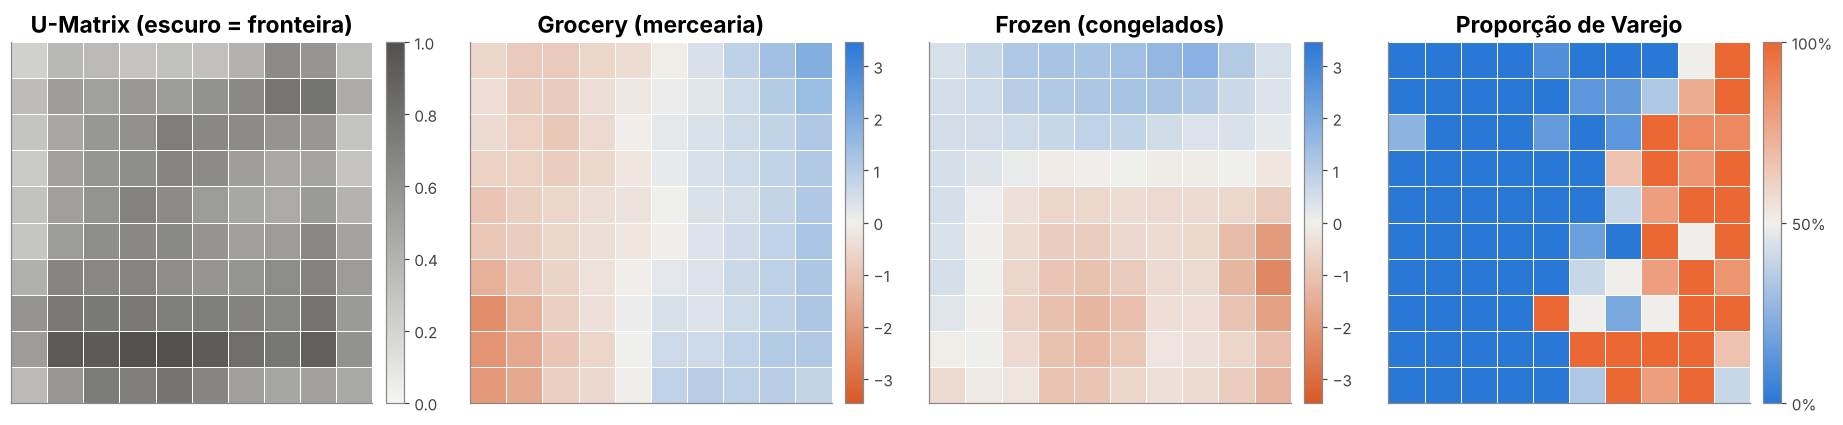

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
paineis = [
    (U, CINZAS, 0, 1, "U-Matrix (escuro = fronteira)"),
    (W[:, :, GASTOS.index("Grocery")], DIVERGENTE, -lim, lim, "Grocery (mercearia)"),
    (W[:, :, GASTOS.index("Frozen")], DIVERGENTE, -lim, lim, "Frozen (congelados)"),
    (prop, CANAL_DIV, 0, 1, "Proporção de Varejo"),
]
for ax, (M, cmap, vmin, vmax, titulo) in zip(axes, paineis):
    im = ax.pcolormesh(M.T, cmap=cmap, vmin=vmin, vmax=vmax, edgecolors="white", linewidth=0.5)
    ax.set_xlim(0, LADO); ax.set_ylim(0, LADO); ax.set_aspect("equal"); ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(titulo, fontsize=15)
    cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.03)
    cb.ax.tick_params(labelsize=10)
    if titulo.startswith("Proporção"):
        cb.set_ticks([0, 0.5, 1]); cb.set_ticklabels(["0%", "50%", "100%"])
plt.tight_layout(); plt.savefig("figuras/03_resumo_slide.png", bbox_inches="tight"); plt.show()

## 7. Resumo da Parte 3 (para o relatório)
- **U-Matrix:** a fronteira mais forte isola a linha de baixo do mapa (clientes com gasto quase nulo em alguma categoria).
  As bordas são homogêneas e o centro tem transições graduais, sem "ilhas" bem separadas.
- **Component planes:** `Milk`/`Grocery`/`Detergents_Paper` crescem da esquerda para a direita (eixo mercearia/limpeza).
  `Frozen`/`Fresh` são altos em cima (eixo perecíveis). `Fresh` quase zero no canto inferior direito.
- **Hit map:** nenhum neurônio vazio, de 1 a 10 clientes por neurônio. O mapa 10×10 está bem dimensionado.
- **Channel:** Horeca à esquerda e Varejo à direita, com 92% de pureza por neurônio, sem o canal ter sido usado no treino.
  Há uma zona de transição no meio.
- **Figuras:** `03_umatrix.png`, `03_component_planes.png`, `03_hitmap.png` e `03_canal_sobre_umatrix.png`.